# Imports

In [73]:
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px
import plotly.figure_factory as ff
import numpy as np
import re

# Constants

In [74]:
EVENT_METADATA_CSV_PATH = '../data/ML Training Metadata For Plotting/event_metadata.csv'
MOLPROBITY_CSV_PATH = '../data/ML Training Metadata For Plotting/molprobity.csv'
DATASET_INFO_CSV_PATH = '../data/ML Training Metadata For Plotting/dataset_info.csv'
LIGAND_DATA_CSV_PATH = '../data/ML Training Metadata For Plotting/event_ligands.csv'


# Define the layout for a system summary

In [75]:
def get_number_of_crystalforms(structure_info):
    return 0

In [118]:
def get_summary_table(
        structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
):
    # Number of datasets
    # Number of soaked datasets
    # Number of hit datasets
    # Number of non hit datasets
    # Total number of observed hits
    # Total unique soaked ligands
    # Number of crystalforms (as estimated from unit cell params and spacegroup)
    # 
    print(event_metadata['ligand_data_idx'])

    number_of_datasets = len(structure_info['dtag'].unique())
    number_of_soaked_datasets = len(structure_info[structure_info['num_ligand_files'] > 0]['dtag'].unique())
    number_of_hit_datasets = len(event_metadata[event_metadata['Confidence'] == 'High']['dtag'].unique())
    number_of_hits = len(event_metadata[event_metadata['Confidence'] == 'High']['dtag'])
    num_soaked_ligands = len(ligand_metadata.loc[event_metadata['ligand_data_idx'].values]['canonical_smiles'].unique())
    number_of_crystalforms = get_number_of_crystalforms(structure_info)
    print(number_of_datasets)
    print(number_of_soaked_datasets)
    print(number_of_hit_datasets)
    print(number_of_hits)
    print(num_soaked_ligands)
    print(number_of_crystalforms)

    ...

In [183]:
def _make_plot(
        summary_table,
        resolution_hist,
        rfree_hist,
        clashscore_hist,
        rama_hist,
        sidechain_hist,
):
    fig = make_subplots(
    rows=3, cols=2,
    # shared_xaxes=True,
    vertical_spacing=0.03,
    specs=[
        [{"type": "table"}, {"type": "histogram"}],
        [{"type": "histogram"}, {"type": "histogram"}],
        [{"type": "histogram"}, {"type": "histogram"}],
    ],
    subplot_titles=(
        'Subplot title1',  'Subplot title2',
        'Subplot title1',  'Subplot title2',
        'Subplot title1',  'Subplot title2',
    )
)
    fig.add_trace(summary_table, row=1, col=1)
    fig.add_trace(resolution_hist, row=1, col=2)
    fig.add_trace(rfree_hist, row=2, col=1)
    fig.add_trace(clashscore_hist, row=2, col=2)
    fig.add_trace(rama_hist, row=3, col=1)
    fig.add_trace(sidechain_hist, row=3, col=2)



    fig.update_layout(
    height=1080,
    showlegend=False,
    title_text="Bitcoin mining stats for 180 days",
)
    
    return fig

In [154]:
def get_summary_table_plot(
    structure_info,
    molprobity,
    event_metadata,
    ligand_metadata
):
    data = get_summary_table(
            structure_info,
    molprobity,
    event_metadata,
    ligand_metadata
    )
    return go.Table(
                header=None,
                cells=dict(values=[[100, 90, 80, 90], [95, 85, 75, 95]]), 
                header_fill_color='rgba(0,0,0,0)')

In [ ]:
def get_resolution_hist_plot(
    structure_info,
    molprobity,
    event_metadata,
    ligand_metadata
    ):

    np.random.seed(1)

    x = molprobity['resolution'].values
    hist_data = x
    group_labels = ['distplot'] # name of the dataset

    # dist_fig = ff.create_distplot(hist_data, group_labels, histnorm=None, 
    #                               xbins=dict(
    #                   start=0,
    #                   end=4,
    #                   size=0.1)
    #                               )

    # return dist_fig.data[0]
    dist_fig = go.Histogram(
        x=hist_data,
        histnorm=None, 
        xbins=dict(
        start=0,
        end=4,
        size=0.1),
    marker=dict(
        color='LightSkyBlue',
        line=dict(
            width=1,
            color='White')
    ),

    )
                                  

    return dist_fig

In [134]:
def get_rfree_hist_plot(
    structure_info,
    molprobity,
    event_metadata,
    ligand_metadata
    ):

    np.random.seed(1)

    x = np.random.randn(1000)
    hist_data = [x]
    group_labels = ['distplot'] # name of the dataset

    dist_fig = ff.create_distplot(hist_data, group_labels, histnorm=None)

    return dist_fig.data[0]

In [135]:
def get_clashscore_hist_plot(
    structure_info,
    molprobity,
    event_metadata,
    ligand_metadata
    ):

    np.random.seed(1)

    x = np.random.randn(1000)
    hist_data = [x]
    group_labels = ['distplot'] # name of the dataset

    dist_fig = ff.create_distplot(hist_data, group_labels, histnorm=None)

    return dist_fig.data[0]

In [136]:
def get_rama_hist_plot(
        structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
    ):

    np.random.seed(1)

    x = np.random.randn(1000)
    hist_data = [x]
    group_labels = ['distplot'] # name of the dataset

    dist_fig = ff.create_distplot(hist_data, group_labels, histnorm=None)

    return dist_fig.data[0]

In [137]:
def get_sidechain_hist_plot(
        structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
    ):

    np.random.seed(1)

    x = np.random.randn(1000)
    hist_data = [x]
    group_labels = ['distplot'] # name of the dataset

    dist_fig = ff.create_distplot(hist_data, group_labels, histnorm=None)

    return dist_fig.data[0]

In [138]:


def plot_system(
        structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
):
    # System table:

    summary_table = get_summary_table_plot(
        structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
    )

    # Resolution distribution
    resolution_hist = get_resolution_hist_plot(
                structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
    )

    # rfree distribution
    rfree_hist = get_rfree_hist_plot(
                structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
    )

    # Clashscore distribution
    clashscore_hist = get_clashscore_hist_plot(
                structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
    )

    # Rama outliers
    rama_hist = get_rama_hist_plot(
                structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
    )

    # Sidechain outliers
    sidechain_hist = get_sidechain_hist_plot(
                structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
    )

    # Make plot
    fig = _make_plot(
        summary_table,
        resolution_hist,
        rfree_hist,
        clashscore_hist,
        rama_hist,
        sidechain_hist,
)
    return fig
    
    ...

# Get the systems used from the event metadata

In [139]:
event_metadata = pd.read_csv(EVENT_METADATA_CSV_PATH)

In [140]:
event_metadata

,Unnamed: 0,idx,event_idx,res_id,ligand_data_idx,pose_data_idx,system,dtag,event_num,Confidence,size,x,y,z,res
0,0,0,3,A_752,0,-1,KAT2B,KAT2B-x0512,3,Medium,330.0,-7.309483,30.332436,1.018453,1.53
1,1,1,3,A_752,1,-1,KAT2B,KAT2B-x0057,3,Medium,330.0,-6.304834,34.353725,1.458763,1.30
2,2,2,3,A_752,2,-1,KAT2B,KAT2B-x0366,3,Low,239.0,-7.424399,29.772423,1.943706,1.37
3,3,3,2,A_752,3,-1,KAT2B,KAT2B-x0145,2,Low,27.0,-19.607510,26.238980,9.805665,1.99
4,4,4,2,A_752,4,-1,KAT2B,KAT2B-x0092,2,Medium,426.0,-20.092825,30.127724,8.305123,1.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53219,53219,53219,1,A_269,53219,-1,TRF1_2,TRF1_2-x0009,1,Low,101.0,24.674423,27.305214,4.796360,1.95
53220,53220,53220,1,A_269,53220,-1,TRF1_2,TRF1_2-x0094,1,Low,710.0,16.767342,42.934605,-8.816437,1.54
53221,53221,53221,2,A_269,53221,-1,TRF1_2,TRF1_2-x0317,2,Low,34.0,21.520440,30.579002,-8.894180,1.81
53222,53222,53222,1,A_269,53222,-1,TRF1_2,TRF1_2-x0571,1,Low,86.0,20.911734,34.345250,-5.565848,1.96


In [141]:
ligand_metadata = pd.read_csv(LIGAND_DATA_CSV_PATH)

In [142]:
ligand_metadata 


,Unnamed: 0,idx,canonical_smiles
0,0,0,[H]C1=NC([H])=C([H])N=C1C(=O)N([H])C1=C([H])C(...
1,1,1,[H]C1=C([H])C(N([H])C(=O)C([H])([H])[H])=C([H]...
2,2,2,[H]C1=C([H])C([H])=C(C([H])([H])C(=O)N2C3=C(C(...
3,3,3,[H]C1=C([H])C2=C(C([H])=C1[H])N(C([H])([H])C([...
4,4,4,[H]N([H])C([H])([H])C1([H])N(S(=O)(=O)C([H])([...
...,...,...,...
53219,53219,53219,[H]c1c([H])c(N([H])C(=S)N([H])[H])c([H])c([H])...
53220,53220,53220,[H]c1nn(C([H])([H])[H])c([H])c1C([H])(N([H])C(...
53221,53221,53221,[H]c1nn([H])c([H])c1S(=O)(=O)N(C([H])([H])[H])...
53222,53222,53222,[H]c1c([H])c(F)c2c(c1[H])N(C(=O)C([H])([H])[H]...


In [143]:
event_metadata['ligand_data_idx'].unique()

array([    0,     1,     2, ..., 53221, 53222, 53223], shape=(53224,))

In [144]:
structure_info = pd.read_csv(DATASET_INFO_CSV_PATH)

In [145]:
structure_info

,Unnamed: 0,a,b,c,alpha,beta,gamma,spacegroup,num_ligand_files,system,dtag
0,0,36.980,85.450,59.820,90.0,96.59,90.0,P 1 21 1,1,KAT2B,KAT2B-x0150
1,1,36.991,83.903,63.477,90.0,91.72,90.0,P 1 21 1,1,KAT2B,KAT2B-x0601
2,2,37.080,86.100,60.170,90.0,96.08,90.0,P 1 21 1,1,KAT2B,KAT2B-x0448
3,3,37.240,87.130,60.680,90.0,96.78,90.0,P 1 21 1,1,KAT2B,KAT2B-x0140
4,4,37.130,86.447,60.310,90.0,95.90,90.0,P 1 21 1,1,KAT2B,KAT2B-x0061
...,...,...,...,...,...,...,...,...,...,...,...
80277,80277,64.539,64.022,114.932,90.0,90.00,90.0,P 21 21 21,1,EBNA_T2,EBNA_T2-x0247
80278,80278,64.395,63.204,114.569,90.0,90.00,90.0,P 21 21 21,1,EBNA_T2,EBNA_T2-x0454
80279,80279,64.450,64.236,115.396,90.0,90.00,90.0,P 21 21 21,1,EBNA_T2,EBNA_T2-x0411
80280,80280,64.369,63.980,114.593,90.0,90.00,90.0,P 21 21 21,1,EBNA_T2,EBNA_T2-x0743


In [146]:
molprobity = pd.read_csv(MOLPROBITY_CSV_PATH)

In [147]:
molprobity

,Unnamed: 0,ramachandran_outliers,ramachandran_favored,rotamer_outliers,beta_deviations,clashscore,rms_bonds,rms_angles,molprobity,resolution,...,resolution_full_low,resolution_full_high,num_reflections,num_reflections_unique,num_reflections_non_outlying,num_reflections_non_outlying_unique,completeness,completeness_unique,system,dtag
0,0,0.63,97.15,1.77,2.0,7.22,0.0132,1.79,1.74,1.99,...,42.725,1.990,24080,2398,23996,2395,94.51,94.11,KAT2B,KAT2B-x0150
1,1,0.95,98.10,0.35,0.0,3.89,0.0139,1.77,1.18,1.48,...,63.449,1.480,64311,6303,64296,6300,99.79,98.89,KAT2B,KAT2B-x0601
2,2,0.63,98.42,1.41,2.0,7.59,0.0144,1.86,1.53,1.79,...,36.871,1.790,33469,3520,33397,3515,94.23,98.46,KAT2B,KAT2B-x0448
3,3,0.95,99.05,1.06,4.0,7.40,0.0154,1.94,1.43,1.28,...,35.304,1.280,97316,8741,97314,8741,98.60,88.97,KAT2B,KAT2B-x0140
4,4,0.63,97.15,1.41,2.0,5.37,0.0138,1.78,1.56,1.60,...,59.990,1.598,45859,4743,45816,4743,91.39,94.88,KAT2B,KAT2B-x0061
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80263,80263,0.34,97.29,0.82,0.0,8.00,0.0147,1.92,1.57,1.62,...,56.274,1.620,60895,5657,60890,5657,99.37,93.91,EBNA_T2,EBNA_T2-x0247
80264,80264,0.00,97.29,1.64,0.0,2.42,0.0146,1.94,1.32,1.61,...,56.135,1.607,61267,5852,61217,5833,99.34,95.78,EBNA_T2,EBNA_T2-x0454
80265,80265,0.68,95.93,0.82,0.0,2.98,0.0153,2.11,1.37,1.62,...,57.698,1.615,61685,5720,61672,5720,99.19,93.45,EBNA_T2,EBNA_T2-x0411
80266,80266,0.34,95.93,0.41,0.0,5.39,0.0143,1.86,1.57,1.73,...,56.121,1.727,50139,4746,50130,4744,99.51,95.40,EBNA_T2,EBNA_T2-x0743


# Get the Molprobity info for datasets

# Tests

## Test one system

In [148]:
system = event_metadata['system'].unique()[0]
system

'KAT2B'

In [149]:
sys_structure_info = structure_info[structure_info['system'] == system]
sys_molprobity= molprobity[molprobity['system'] == system]
sys_event_metadata = event_metadata[event_metadata['system'] == system]
ligand_metadata = ligand_metadata

In [191]:
plot_system(
        sys_structure_info,
        sys_molprobity,
        sys_event_metadata,
        ligand_metadata
)

0        0
1        1
2        2
3        3
4        4
      ... 
452    452
453    453
454    454
455    455
456    456
Name: ligand_data_idx, Length: 457, dtype: int64
367
367
55
67
292
0


ValueError: 
    Invalid value of type 'builtins.str' received for the 'xaxis' property of histogram
        Received value: 'x'

    The 'xaxis' property is an identifier of a particular
    subplot, of type 'x', that may be specified as:
      - the string 'x' optionally followed by an integer >= 1
        (e.g. 'x', 'x1', 'x2', 'x3', etc.)

## TEST Plots

In [159]:
event_metadata['ligand_data_idx'].values

array([    0,     1,     2, ..., 53221, 53222, 53223], shape=(53224,))

In [117]:
ligand_metadata.loc[[int(x) for x in event_metadata['ligand_data_idx'].values]]

,Unnamed: 0,idx,canonical_smiles
0,0,0,[H]C1=NC([H])=C([H])N=C1C(=O)N([H])C1=C([H])C(...
1,1,1,[H]C1=C([H])C(N([H])C(=O)C([H])([H])[H])=C([H]...
2,2,2,[H]C1=C([H])C([H])=C(C([H])([H])C(=O)N2C3=C(C(...
3,3,3,[H]C1=C([H])C2=C(C([H])=C1[H])N(C([H])([H])C([...
4,4,4,[H]N([H])C([H])([H])C1([H])N(S(=O)(=O)C([H])([...
...,...,...,...
53219,53219,53219,[H]c1c([H])c(N([H])C(=S)N([H])[H])c([H])c([H])...
53220,53220,53220,[H]c1nn(C([H])([H])[H])c([H])c1C([H])(N([H])C(...
53221,53221,53221,[H]c1nn([H])c([H])c1S(=O)(=O)N(C([H])([H])[H])...
53222,53222,53222,[H]c1c([H])c(F)c2c(c1[H])N(C(=O)C([H])([H])[H]...


In [ ]:
# Get 

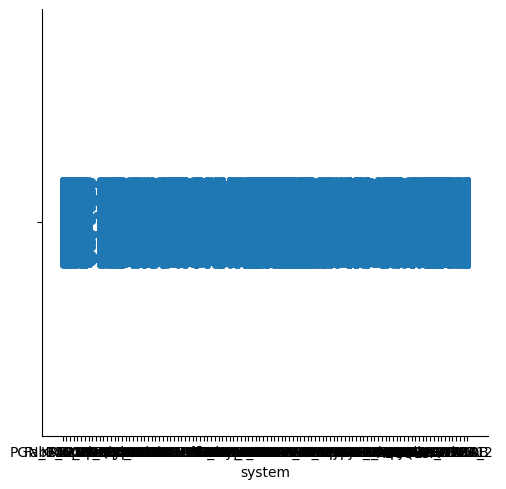

In [ ]:
sns.catplot(
    data=event_metadata, 
    x='system',
    )

In [180]:
df = pd.read_csv("https://raw.githubusercontent.com/plotly/datasets/master/Mining-BTC-180.csv")

for i, row in enumerate(df["Date"]):
    p = re.compile(" 00:00:00")
    datetime = p.split(df["Date"][i])[0]
    df.iloc[i, 1] = datetime

fig = make_subplots(
    rows=1, cols=2,
    # shared_xaxes=True,
    vertical_spacing=0.03,
    specs=[[{"type": "table"}, {"type": "histogram"}],
           ],
           subplot_titles=('Subplot title1',  'Subplot title2')
)



fig.add_trace(
    go.Table(
        header=dict(
            values=["Date", "Number<br>Transactions", "Output<br>Volume (BTC)",
                    "Market<br>Price", "Hash<br>Rate", "Cost per<br>trans-USD",
                    "Mining<br>Revenue-USD", "Trasaction<br>fees-BTC"],
            font=dict(size=10),
            align="left"
        ),
        cells=dict(
            values=[df[k].tolist() for k in df.columns[1:]],
            align = "left")
    ),
    row=1, col=1
)

import plotly.figure_factory as ff
import numpy as np
np.random.seed(1)

x = np.random.randn(1000)
hist_data = x
group_labels = ['distplot'] # name of the dataset

# dist_fig = ff.create_distplot(hist_data, group_labels, histnorm=None,     )



# fig.add_trace(
#     dist_fig.data[0],
#     row=1, col=2,
# )

dist_fig = go.Histogram(
        x=hist_data,
        histnorm=None, 
                                  xbins=dict(
                      start=0,
                      end=4,
                      size=0.1),
    marker=dict(
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                                  )

fig.add_trace(
    dist_fig,
    row=1, col=2,
)

# df = px.data.medals_long()

# medal_fig = px.bar(df, x="medal", y="count", color="nation",
#              pattern_shape="nation", pattern_shape_sequence=[".", "x", "+"])



# fig.add_trace(
#     medal_fig.data[0],
#     row=1, col=2
# )
# fig.add_trace(
#     medal_fig.data[1],
#     row=1, col=2
# )


# fig.add_trace(
#     go.Scatter(
#         x=df["Date"],
#         y=df["Mining-revenue-USD"],
#         mode="lines",
#         name="mining revenue"
#     ),
#     row=1, col=2
# )
fig.update_layout(barmode='stack')

# fig.update_layout(histnorm='probability')


fig.update_layout(
    height=800,
    showlegend=False,
    title_text="Bitcoin mining stats for 180 days",
)

fig.show()

In [ ]:
medal_fig

NameError: name 'medal_fig' is not defined

In [ ]:
fig.data[1]

AttributeError: 'Scatter' object has no attribute 'show'

In [ ]:
fig = go.Figure(
        go.Table(
                header=None,
                cells=dict(values=[[100, 90, 80, 90], [95, 85, 75, 95]]), 
                header_fill_color='rgba(0,0,0,0)')
    )
fig